<a href="https://colab.research.google.com/github/DEEPIKAGRACE22/PS-7---AI-Assisted-Quality-Inspection-IBM-x-MAH-Quantum-project-/blob/main/ps7_compare_all_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PS-7: Compare ALL models on the same held-out test set
Evaluates every `.pt` you upload (e.g. `old_trained.pt`, `old_finetuned.pt`, `best_v1.pt`, `best_v2.pt`) on the identical
180 test images (30 per class, seed 42), and produces one per-class comparison table + chart.

**Name your files clearly before uploading** — the filename becomes the model's label in the report.
**Fairness check (important):** if the old fine-tuned model was trained on any of these 180 test images, its numbers are inflated and must not be reported as test results.

In [1]:
%pip install -q ultralytics kagglehub pandas matplotlib
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU will work, just slower)")

GPU: none (CPU will work, just slower)


## 1. Rebuild the test split (identical to the training notebook)

In [2]:
import random, shutil, xml.etree.ElementTree as ET
from pathlib import Path
import kagglehub

SEED, TEST_PER_CLASS = 42, 30
CLASS_NAMES = ["crazing","inclusion","patches","pitted_surface","rolled-in_scale","scratches"]
CLASS_TO_ID = {n:i for i,n in enumerate(CLASS_NAMES)}
IMG_EXT = {".jpg",".jpeg",".png",".bmp"}
OUT = Path("/content/neu_test_only")

SRC = Path(kagglehub.dataset_download("kaustubhdikshit/neu-surface-defect-database")) / "NEU-DET"
xml_by_stem = {p.stem: p for p in SRC.rglob("*.xml")}

def voc_to_yolo(xml_path):
    root = ET.parse(xml_path).getroot()
    w = int(root.find("size").findtext("width")); h = int(root.find("size").findtext("height"))
    lines = []
    for obj in root.findall("object"):
        b = obj.find("bndbox")
        x1 = max(0, min(float(b.findtext("xmin")), w)); x2 = max(0, min(float(b.findtext("xmax")), w))
        y1 = max(0, min(float(b.findtext("ymin")), h)); y2 = max(0, min(float(b.findtext("ymax")), h))
        lines.append(f"{CLASS_TO_ID[obj.findtext('name')]} {(x1+x2)/2/w:.6f} {(y1+y2)/2/h:.6f} {(x2-x1)/w:.6f} {(y2-y1)/h:.6f}")
    return "\n".join(lines) + "\n"

rng = random.Random(SEED)          # one shared RNG, classes in fixed order -> same split as before
test_imgs = []
for cls in CLASS_NAMES:
    tr = sorted(p for p in (SRC/"train"/"images"/cls).iterdir() if p.suffix.lower() in IMG_EXT)
    rng.shuffle(tr)
    test_imgs += tr[:TEST_PER_CLASS]

if OUT.exists(): shutil.rmtree(OUT)
(OUT/"images"/"test").mkdir(parents=True); (OUT/"labels"/"test").mkdir(parents=True)
for img in test_imgs:
    shutil.copy2(img, OUT/"images"/"test"/img.name)
    (OUT/"labels"/"test"/f"{img.stem}.txt").write_text(voc_to_yolo(xml_by_stem[img.stem]))

(OUT/"data.yaml").write_text(
    f"path: {OUT}\ntrain: images/test\nval: images/test\ntest: images/test\nnames:\n"
    + "".join(f"  {i}: {n}\n" for i,n in enumerate(CLASS_NAMES)))
print("Test images:", len(list((OUT/'images'/'test').glob('*'))))
Path("/content/test_split_filenames.txt").write_text("\n".join(sorted(p.name for p in test_imgs)))

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Test images: 180


3351

## 2. Upload your model weights (.pt files)
Select all of them at once. Suggested names: `old_trained.pt`, `old_finetuned.pt`, `best_v1.pt`, `best_v2.pt`.

In [3]:
from google.colab import files
uploaded = files.upload()
MODELS = {Path(n).stem: Path("/content")/n for n in uploaded if n.lower().endswith(".pt")}
print("Models to evaluate:", list(MODELS))
assert MODELS, "No .pt files uploaded"

Saving best_v1.pt to best_v1.pt
Saving best_v2.pt to best_v2.pt
Saving old_finetuned.pt to old_finetuned.pt
Saving old_trained.pt to old_trained.pt
Models to evaluate: ['best_v1', 'best_v2', 'old_finetuned', 'old_trained']


## 3. Evaluate every model on the same test set

In [4]:
import pandas as pd
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"
rows = []
for tag, w in MODELS.items():
    try:
        m = YOLO(str(w)).val(data=str(OUT/"data.yaml"), split="test", imgsz=640, batch=16,
                             device=DEVICE, plots=True, project="/content/cmp_runs", name=tag, exist_ok=True)
    except Exception as e:
        print(f"!! {tag} failed: {e}"); continue
    if len(m.names) != 6:
        print(f"!! {tag}: has {len(m.names)} classes, expected 6 - skipped"); continue
    for i, c in enumerate(m.box.ap_class_index):
        rows.append(dict(model=tag, cls=m.names[c], precision=float(m.box.p[i]), recall=float(m.box.r[i]),
                         mAP50=float(m.box.ap50[i]), mAP50_95=float(m.box.maps[c])))
    rows.append(dict(model=tag, cls="ALL (mean)", precision=float(m.box.mp), recall=float(m.box.mr),
                     mAP50=float(m.box.map50), mAP50_95=float(m.box.map)))

long = pd.DataFrame(rows)
long.to_csv("/content/all_models_per_class.csv", index=False)
long.round(3)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.192 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 417.4±141.4 MB/s, size: 18.1 KB)
val: Scanning /content/neu_test_only/labels/test... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 1.2Kit/s 0.2s
val: /content/neu_test_only/images/test/patches_198.jpg: 1 duplicate labels removed
val: New cache created: /content/neu_test_only/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.7s/it 44.4s
                   all        180        415     

,model,cls,precision,recall,mAP50,mAP50_95
0,best_v1,crazing,0.461,0.243,0.307,0.111
1,best_v1,inclusion,0.669,0.682,0.748,0.359
2,best_v1,patches,0.678,0.716,0.814,0.529
3,best_v1,pitted_surface,0.655,0.861,0.795,0.577
4,best_v1,rolled-in_scale,0.516,0.604,0.585,0.267
5,best_v1,scratches,0.814,0.781,0.883,0.436
6,best_v1,ALL (mean),0.632,0.648,0.689,0.380
7,best_v2,crazing,0.605,0.300,0.479,0.182
8,best_v2,inclusion,0.777,0.745,0.815,0.410
9,best_v2,patches,0.823,0.784,0.878,0.533


## 4. Side-by-side tables and chart


=== precision ===


model,best_v1,best_v2,old_finetuned,old_trained
cls,,,,
ALL (mean),0.632,0.761,0.625,0.748
crazing,0.461,0.605,0.502,0.528
inclusion,0.669,0.777,0.596,0.748
patches,0.678,0.823,0.725,0.789
pitted_surface,0.655,0.791,0.795,0.857
rolled-in_scale,0.516,0.709,0.428,0.734
scratches,0.814,0.860,0.705,0.831



=== recall ===


model,best_v1,best_v2,old_finetuned,old_trained
cls,,,,
ALL (mean),0.648,0.697,0.665,0.681
crazing,0.243,0.300,0.243,0.257
inclusion,0.682,0.745,0.791,0.703
patches,0.716,0.784,0.750,0.807
pitted_surface,0.861,0.806,0.778,0.778
rolled-in_scale,0.604,0.634,0.449,0.594
scratches,0.781,0.911,0.982,0.946



=== mAP50 ===


model,best_v1,best_v2,old_finetuned,old_trained
cls,,,,
ALL (mean),0.689,0.768,0.694,0.758
crazing,0.307,0.479,0.304,0.391
inclusion,0.748,0.815,0.790,0.808
patches,0.814,0.878,0.761,0.822
pitted_surface,0.795,0.867,0.856,0.869
rolled-in_scale,0.585,0.643,0.490,0.697
scratches,0.883,0.930,0.961,0.963



=== mAP50_95 ===


model,best_v1,best_v2,old_finetuned,old_trained
cls,,,,
ALL (mean),0.380,0.433,0.389,0.413
crazing,0.111,0.182,0.105,0.147
inclusion,0.359,0.410,0.412,0.425
patches,0.529,0.533,0.470,0.498
pitted_surface,0.577,0.627,0.576,0.585
rolled-in_scale,0.267,0.319,0.214,0.309
scratches,0.436,0.527,0.560,0.518


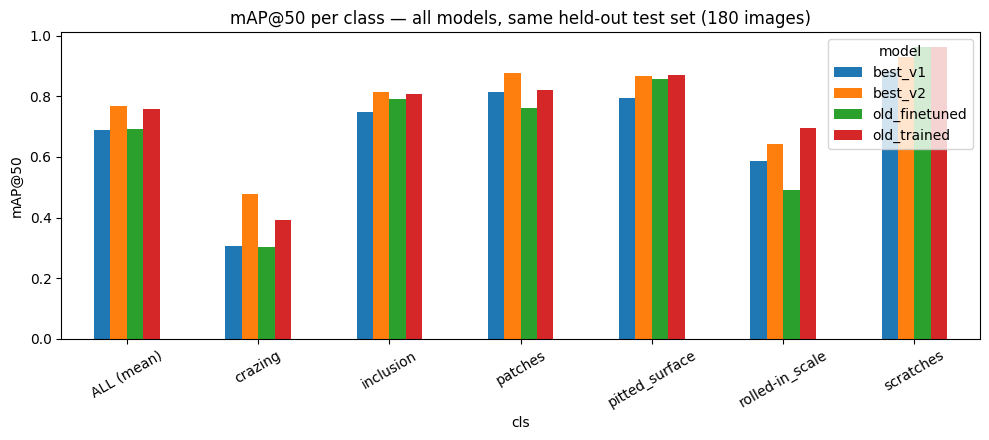

,precision,recall,mAP50,mAP50_95
model,,,,
best_v2,0.761,0.697,0.768,0.433
old_trained,0.748,0.681,0.758,0.413
old_finetuned,0.625,0.665,0.694,0.389
best_v1,0.632,0.648,0.689,0.380


In [5]:
import matplotlib.pyplot as plt

for metric in ["precision", "recall", "mAP50", "mAP50_95"]:
    print(f"\n=== {metric} ===")
    display(long.pivot(index="cls", columns="model", values=metric).round(3))

wide = long.pivot(index="cls", columns="model", values="mAP50")
ax = wide.plot.bar(figsize=(10, 4.5), rot=30)
ax.set_title("mAP@50 per class — all models, same held-out test set (180 images)")
ax.set_ylabel("mAP@50"); plt.tight_layout()
plt.savefig("/content/all_models_map50.png", dpi=150); plt.show()

summary = long[long.cls == "ALL (mean)"].set_index("model")[["precision","recall","mAP50","mAP50_95"]].round(3)
summary.to_csv("/content/all_models_summary.csv")
display(summary.sort_values("mAP50", ascending=False))

## 5. Download results

In [6]:
import zipfile
with zipfile.ZipFile("/content/model_comparison.zip", "w") as z:
    for f in ["all_models_per_class.csv", "all_models_summary.csv", "all_models_map50.png", "test_split_filenames.txt"]:
        z.write(f"/content/{f}", f)
files.download("/content/model_comparison.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>